# Warehouse Operations & Process Improvement Analysis
**Objective:** Identify where the warehouse loses processing time, why it may be happening, and what to investigate first.
**Dataset:** 10,000 simulated warehouse orders (August 2026), generated in Excel with built-in patterns. Not Amazon data.
**Method:** Load and clean the data, calculate KPIs, investigate by zone, shift, workload and worker experience, then chart the results. Results were cross-checked against the Excel PivotTables.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw_data.csv")
print(df.shape)
df.head()

(10000, 13)


,Order Id,Date,Shift,Zone,Product Category,Items,Priority,Pick Time,Pack Time,Processing Time,Error,Worker Experience,Orders in Shift
0,O0001,11/08/2026,Evening,C,Home,4,Standard,10.3,4.1,14.4,No,Experienced,166
1,O0002,29/08/2026,Evening,B,Electronics,5,Priority,6.4,3.9,10.3,No,Experienced,130
2,O0003,25/08/2026,Evening,A,Electronics,8,Standard,8.3,3.9,12.2,No,Experienced,128
3,O0004,11/08/2026,Afternoon,C,Electronics,2,Priority,6.7,3.1,9.8,No,Experienced,102
4,O0005,22/08/2026,Morning,C,Clothing,9,Priority,11.4,4.8,16.2,No,Experienced,98


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order Id           10000 non-null  str    
 1   Date               10000 non-null  str    
 2   Shift              10000 non-null  str    
 3   Zone               10000 non-null  str    
 4   Product Category   10000 non-null  str    
 5   Items              10000 non-null  int64  
 6   Priority           10000 non-null  str    
 7   Pick Time          10000 non-null  float64
 8   Pack Time          10000 non-null  float64
 9   Processing Time    10000 non-null  float64
 10  Error              10000 non-null  str    
 11  Worker Experience  10000 non-null  str    
 12  Orders in Shift    10000 non-null  int64  
dtypes: float64(3), int64(2), str(8)
memory usage: 1.5 MB


In [3]:
print("Missing values per column:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Order IDs:", df["Order Id"].duplicated().sum())

Missing values per column:
Order Id             0
Date                 0
Shift                0
Zone                 0
Product Category     0
Items                0
Priority             0
Pick Time            0
Pack Time            0
Processing Time      0
Error                0
Worker Experience    0
Orders in Shift      0
dtype: int64
Duplicate rows: 0
Duplicate Order IDs: 0


In [4]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df["Date"].dtype

dtype('<M8[us]')

In [5]:
print("Pick or Pack time <= 0:", (df["Pick Time"] <= 0).sum() + (df["Pack Time"] <= 0).sum())
print("Items outside 1-10:", ((df["Items"] < 1) | (df["Items"] > 10)).sum())
print("Dates outside Aug 2026:", ((df["Date"] < "2026-08-01") | (df["Date"] > "2026-08-31")).sum())
print("Processing not equal to Pick + Pack:", ((df["Processing Time"] - (df["Pick Time"] + df["Pack Time"])).abs() > 0.01).sum())
print(df["Zone"].value_counts())
print(df["Shift"].value_counts())
df.describe()

Pick or Pack time <= 0: 0
Items outside 1-10: 0
Dates outside Aug 2026: 0
Processing not equal to Pick + Pack: 0
Zone
C    2528
B    2527
A    2473
D    2472
Name: count, dtype: int64
Shift
Evening      4044
Morning      3011
Afternoon    2945
Name: count, dtype: int64


,Date,Items,Pick Time,Pack Time,Processing Time,Orders in Shift
count,10000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000
mean,2026-08-16 01:26:24,5.484400,7.873110,4.274370,12.14748,110.858600
min,2026-08-01 00:00:00,1.000000,3.400000,2.600000,6.20000,72.000000
25%,2026-08-08 00:00:00,3.000000,6.300000,3.700000,10.30000,96.000000
50%,2026-08-16 00:00:00,5.000000,7.600000,4.200000,11.90000,105.000000
75%,2026-08-24 00:00:00,8.000000,9.200000,4.800000,13.80000,127.000000
max,2026-08-31 00:00:00,10.000000,17.200000,6.900000,22.90000,166.000000
std,NaN,2.868097,2.082312,0.824976,2.56972,19.587546


In [6]:
df["Delayed Flag"] = (df["Processing Time"] > 15).astype(int)
df["Error Flag"] = (df["Error"] == "Yes").astype(int)
df["Workload Band"] = pd.cut(df["Orders in Shift"], bins=[0, 99, 129, 10000], labels=["1-Low (<100)", "2-Medium (100-129)", "3-High (130+)"])
df.head()

,Order Id,Date,Shift,Zone,Product Category,Items,Priority,Pick Time,Pack Time,Processing Time,Error,Worker Experience,Orders in Shift,Delayed Flag,Error Flag,Workload Band
0,O0001,2026-08-11,Evening,C,Home,4,Standard,10.3,4.1,14.4,No,Experienced,166,0,0,3-High (130+)
1,O0002,2026-08-29,Evening,B,Electronics,5,Priority,6.4,3.9,10.3,No,Experienced,130,0,0,3-High (130+)
2,O0003,2026-08-25,Evening,A,Electronics,8,Standard,8.3,3.9,12.2,No,Experienced,128,0,0,2-Medium (100-129)
3,O0004,2026-08-11,Afternoon,C,Electronics,2,Priority,6.7,3.1,9.8,No,Experienced,102,0,0,2-Medium (100-129)
4,O0005,2026-08-22,Morning,C,Clothing,9,Priority,11.4,4.8,16.2,No,Experienced,98,1,0,1-Low (<100)


In [7]:
print("Delayed orders:", df["Delayed Flag"].sum())
print("Delayed %:", round(df["Delayed Flag"].mean() * 100, 1))
print("Error rate %:", round(df["Error Flag"].mean() * 100, 1))
print("Average processing time:", round(df["Processing Time"].mean(), 1))

Delayed orders: 1375
Delayed %: 13.8
Error rate %: 4.7
Average processing time: 12.1


In [8]:
checks = {
    "Missing values": int(df.isnull().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Duplicate Order IDs": int(df["Order Id"].duplicated().sum()),
    "Pick or Pack time <= 0": int(((df["Pick Time"] <= 0) | (df["Pack Time"] <= 0)).sum()),
    "Items outside 1-10": int(((df["Items"] < 1) | (df["Items"] > 10)).sum()),
    "Dates outside Aug 2026": int(((df["Date"] < "2026-08-01") | (df["Date"] > "2026-08-31")).sum()),
    "Processing != Pick + Pack": int(((df["Processing Time"] - (df["Pick Time"] + df["Pack Time"])).abs() > 0.01).sum()),
}

validation = pd.DataFrame({"Check": list(checks.keys()), "Issues found": list(checks.values())})
validation["Result"] = validation["Issues found"].apply(lambda n: "Pass" if n == 0 else "Fail")
print(validation.to_string(index=False))

assert (validation["Issues found"] == 0).all(), "Validation failed"

                    Check  Issues found Result
           Missing values             0   Pass
           Duplicate rows             0   Pass
      Duplicate Order IDs             0   Pass
   Pick or Pack time <= 0             0   Pass
       Items outside 1-10             0   Pass
   Dates outside Aug 2026             0   Pass
Processing != Pick + Pack             0   Pass


In [9]:
df.to_csv("../data/clean_data.csv", index=False)
print("Saved")

Saved


In [10]:
kpis = {
    "Total orders": len(df),
    "Avg processing time (min)": round(df["Processing Time"].mean(), 1),
    "Avg pick time (min)": round(df["Pick Time"].mean(), 1),
    "Avg pack time (min)": round(df["Pack Time"].mean(), 1),
    "Error rate (%)": round(df["Error Flag"].mean() * 100, 1),
    "Delayed orders (%)": round(df["Delayed Flag"].mean() * 100, 1),
}

for name, value in kpis.items():
    print(name, ":", value)

Total orders : 10000
Avg processing time (min) : 12.1
Avg pick time (min) : 7.9
Avg pack time (min) : 4.3
Error rate (%) : 4.7
Delayed orders (%) : 13.8


In [11]:
def summarise(column):
    table = df.groupby(column, observed=True).agg(
        avg_processing_time=("Processing Time", "mean"),
        error_rate_pct=("Error Flag", "mean"),
        delayed_pct=("Delayed Flag", "mean"),
    )
    table["error_rate_pct"] = table["error_rate_pct"] * 100
    table["delayed_pct"] = table["delayed_pct"] * 100
    return table.round(1)

In [12]:
summarise("Zone")

,avg_processing_time,error_rate_pct,delayed_pct
Zone,,,
A,10.7,3.5,3.1
B,11.9,3.9,8.6
C,14.1,7.7,33.8
D,11.9,3.6,9.2


In [13]:
summarise("Shift")

,avg_processing_time,error_rate_pct,delayed_pct
Shift,,,
Afternoon,11.7,4.2,10.0
Evening,12.8,5.5,19.7
Morning,11.7,3.9,9.4


In [14]:
summarise("Workload Band")

,avg_processing_time,error_rate_pct,delayed_pct
Workload Band,,,
1-Low (<100),11.7,4.0,10.0
2-Medium (100-129),12.1,5.0,13.4
3-High (130+),12.8,5.0,20.2


In [15]:
summarise("Worker Experience")

,avg_processing_time,error_rate_pct,delayed_pct
Worker Experience,,,
Experienced,11.4,3.9,6.4
New,13.8,6.4,30.9


In [16]:
df.pivot_table(values="Processing Time", index="Zone", columns="Shift", aggfunc="mean").round(1)

Shift,Afternoon,Evening,Morning
Zone,,,
A,10.3,11.3,10.3
B,11.4,12.5,11.4
C,13.6,15.0,13.4
D,11.4,12.5,11.5


In [17]:
print("Share of all orders by zone (%):")
print((df["Zone"].value_counts(normalize=True) * 100).round(1))
print()
print("Share of delayed orders by zone (%):")
print((df[df["Delayed Flag"] == 1]["Zone"].value_counts(normalize=True) * 100).round(1))

Share of all orders by zone (%):
Zone
C    25.3
B    25.3
A    24.7
D    24.7
Name: proportion, dtype: float64

Share of delayed orders by zone (%):
Zone
C    62.1
D    16.5
B    15.8
A     5.6
Name: proportion, dtype: float64


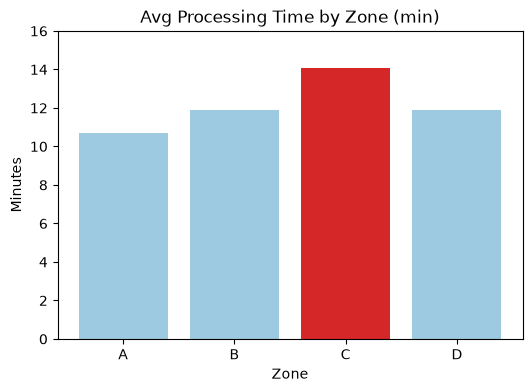

In [18]:
import os
os.makedirs("../charts/v1", exist_ok=True)

zone = summarise("Zone")
colours = ["#d62728" if z == "C" else "#9ecae1" for z in zone.index]

plt.figure(figsize=(6, 4))
plt.bar(zone.index, zone["avg_processing_time"], color=colours)
plt.title("Avg Processing Time by Zone (min)")
plt.xlabel("Zone")
plt.ylabel("Minutes")
plt.ylim(0, 16)
plt.savefig("../charts/v1/1_processing_time_by_zone.png", dpi=150, bbox_inches="tight")
plt.show()

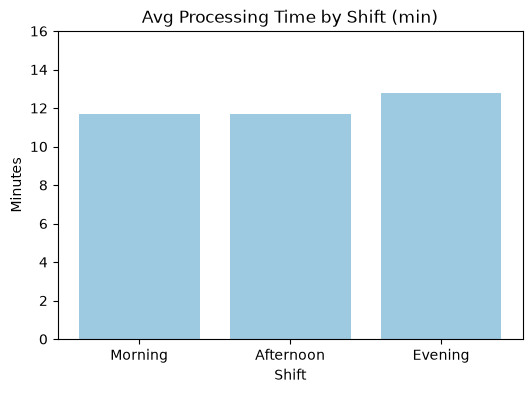

In [19]:
shift = summarise("Shift").reindex(["Morning", "Afternoon", "Evening"])

plt.figure(figsize=(6, 4))
plt.bar(shift.index, shift["avg_processing_time"], color="#9ecae1")
plt.title("Avg Processing Time by Shift (min)")
plt.xlabel("Shift")
plt.ylabel("Minutes")
plt.ylim(0, 16)
plt.savefig("../charts/v1/2_processing_time_by_shift.png", dpi=150, bbox_inches="tight")
plt.show()

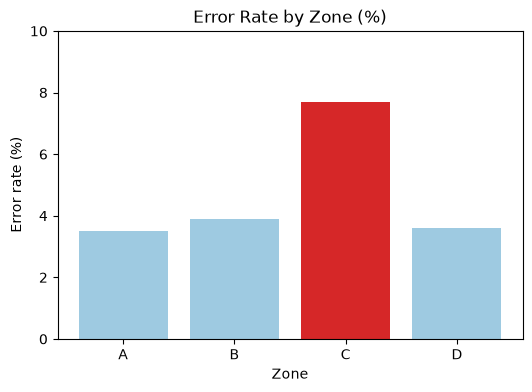

In [20]:
plt.figure(figsize=(6, 4))
plt.bar(zone.index, zone["error_rate_pct"], color=colours)
plt.title("Error Rate by Zone (%)")
plt.xlabel("Zone")
plt.ylabel("Error rate (%)")
plt.ylim(0, 10)
plt.savefig("../charts/v1/3_error_rate_by_zone.png", dpi=150, bbox_inches="tight")
plt.show()

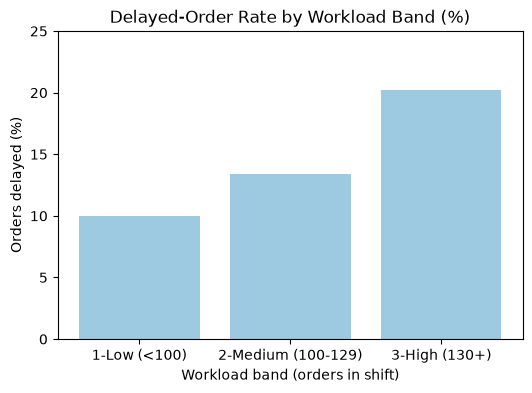

In [21]:
workload = summarise("Workload Band")

plt.figure(figsize=(6, 4))
plt.bar(workload.index, workload["delayed_pct"], color="#9ecae1")
plt.title("Delayed-Order Rate by Workload Band (%)")
plt.xlabel("Workload band (orders in shift)")
plt.ylabel("Orders delayed (%)")
plt.ylim(0, 25)
plt.savefig("../charts/v1/4_delayed_rate_by_workload.png", dpi=150, bbox_inches="tight")
plt.show()

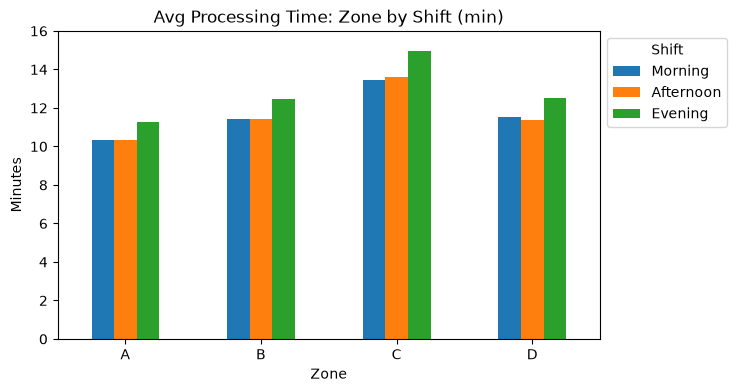

In [22]:
zone_shift = df.pivot_table(values="Processing Time", index="Zone", columns="Shift", aggfunc="mean")
zone_shift = zone_shift[["Morning", "Afternoon", "Evening"]]

zone_shift.plot(kind="bar", figsize=(7, 4))
plt.title("Avg Processing Time: Zone by Shift (min)")
plt.xlabel("Zone")
plt.ylabel("Minutes")
plt.ylim(0, 16)
plt.xticks(rotation=0)
plt.legend(title="Shift", loc="upper left", bbox_to_anchor=(1, 1))
plt.savefig("../charts/v1/5_zone_by_shift.png", dpi=150, bbox_inches="tight")
plt.show()

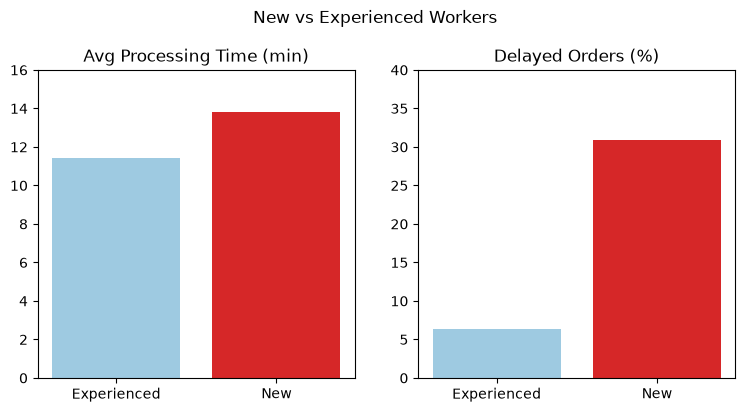

In [23]:
exp = summarise("Worker Experience")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].bar(exp.index, exp["avg_processing_time"], color=["#9ecae1", "#d62728"])
axes[0].set_title("Avg Processing Time (min)")
axes[0].set_ylim(0, 16)
axes[1].bar(exp.index, exp["delayed_pct"], color=["#9ecae1", "#d62728"])
axes[1].set_title("Delayed Orders (%)")
axes[1].set_ylim(0, 40)
fig.suptitle("New vs Experienced Workers", y=1.03)
plt.savefig("../charts/v1/6_new_vs_experienced.png", dpi=150, bbox_inches="tight")
plt.show()

## Findings

1. **Zone C is the main bottleneck:** average processing time is 14.1 minutes, its error rate is 7.7%, and 33.8% of its own orders are delayed. Although it handles about 25% of all orders, it accounts for about 62% of all delayed orders.
2. **Evening is the slowest shift:** 12.8 min and 19.7% delayed. The worst combination is Zone C in the evening at 15.0 min.
3. **New workers are slower and less accurate:** 13.8 vs 11.4 min, 6.4% vs 3.9% errors, 30.9% vs 6.4% delayed.
4. **Delays rise with workload:** 20.2% delayed in high-workload shifts vs 10.0% in low-workload shifts.

**Interpretation caution:** These are patterns that warrant investigation, not proven causes. Workload and evening shifts overlap, so their effects cannot be separated with this data.

## Recommendation

Prioritise an operational review of Zone C during peak evening periods, focusing on staffing allocation, product placement and new-worker support. Suggested test: trial an additional experienced picker in Zone C during the busiest evening period for about two weeks, and compare processing time, delayed % and error rate against the current baseline.

## Limitations

This is a simulated student dataset designed to demonstrate operational analysis. It does not represent actual Amazon data. The patterns were built into the data, so the project shows the analytical method, not real warehouse behaviour. The 15-minute delay threshold is an assumption.